# Home Credit Exploratory Data Analysis

This notebook executes the approved `eda_plan.md` against the supplied application files. It uses descriptive summaries and visualizations to assess data quality, outcome patterns, feature availability, and modeling readiness. Results describe this sample; they do not establish causal effects or approve an underwriting policy.

## Table of contents

1. [Introduction](#Introduction)  
2. [Business problem and scope](#Business-problem-and-scope)  
3. [Data description](#Data-description)  
4. [Standing checks](#Standing-checks)  
5. [Exploration questions](#Exploration-questions-in-approved-order)  
6. [Results and implications](#Results-and-implications)  
7. [AI Disclosure](#AI-Disclosure)

Within the exploration section, questions Q1–Q3 establish data integrity and use constraints; Q4–Q12 describe the target and feature relationships; and Q13–Q17 assess modeling, business-claim, and data-readiness limits.

## Introduction

This exploratory data analysis examines the supplied Home Credit application data before any predictive modeling is attempted. Its purpose is to establish what the data represents, assess whether its values and train/test partitions are credible and comparable, identify descriptive relationships with payment difficulty, and document limitations that affect responsible lending use.

The notebook proceeds from data integrity and timing checks to outcome and feature exploration, then closes with implications for the analytics approach. All relationships are descriptive; they should not be read as evidence of causality, credit-policy suitability, or model performance.

## Business problem and scope

The project seeks to support consumer-lending repayment-risk assessment by identifying application-time signals associated with the supplied `TARGET` outcome. The Business Problem Statement frames success more broadly in terms of approval decisions, credit losses, net interest margin (NIM), processing efficiency, and an improvement over rigid rules. This EDA tests what the supplied application files can substantiate before modeling begins.

The available label is **payment difficulty**, not a fully specified conventional default outcome: its delinquency threshold and horizon are not provided. Likewise, the current files do not contain production decisions, funded balances, realized losses, NIM, workflow times, an incumbent-rule baseline, or verified banking status. Consequently, this notebook focuses on data quality, descriptive risk relationships, and the evidence needed to make those broader business claims responsibly.

### How to read the analysis

Tables report group sizes alongside rates so small groups are not mistaken for stable patterns. Plot axes state whether values are rates, counts, or percentages. Interpretations immediately follow the relevant outputs and distinguish observed associations from operational, causal, or policy conclusions.

In [1]:
# Load the supplied files once and define reusable descriptive-summary helpers.
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display
import matplotlib.pyplot as plt

pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda value: f'{value:,.4f}')

# Support execution from either the project root or the notebooks directory.
project_root = Path.cwd() if (Path.cwd() / 'data' / 'raw').exists() else Path.cwd().parent
data_dir = project_root / 'data' / 'raw'
train = pd.read_csv(data_dir / 'application_train.csv')
test = pd.read_csv(data_dir / 'application_test.csv')
dictionary = pd.read_csv(data_dir / 'HomeCredit_columns_description.csv', encoding='latin1')
inquiry_columns = ['AMT_REQ_CREDIT_BUREAU_HOUR', 'AMT_REQ_CREDIT_BUREAU_DAY', 'AMT_REQ_CREDIT_BUREAU_WEEK', 'AMT_REQ_CREDIT_BUREAU_MON', 'AMT_REQ_CREDIT_BUREAU_QRT', 'AMT_REQ_CREDIT_BUREAU_YEAR']

def rate_by_group(frame, column):
    result = frame.groupby(column, dropna=False).agg(rows=('TARGET', 'size'), target_count=('TARGET', 'sum'), target_rate=('TARGET', 'mean')).reset_index()
    return result.sort_values(['target_rate', 'rows'], ascending=[False, False])

def named_rate_by_group(frame, column):
    result = rate_by_group(frame, column).rename(columns={column: 'value'})
    result.insert(0, 'feature', column)
    return result[['feature', 'value', 'rows', 'target_count', 'target_rate']]

def binned_target_rate(frame, column, bins=5):
    subset = frame[[column, 'TARGET']].dropna().copy()
    if subset.empty or subset[column].nunique() < 2:
        return pd.DataFrame(columns=['feature', 'bin', 'rows', 'target_count', 'target_rate'])
    groups = pd.qcut(subset[column], q=min(bins, subset[column].nunique()), duplicates='drop')
    result = subset.groupby(groups, observed=False).agg(rows=('TARGET', 'size'), target_count=('TARGET', 'sum'), target_rate=('TARGET', 'mean')).reset_index(names='bin')
    result.insert(0, 'feature', column)
    return result

print(f'Train shape: {train.shape}; test shape: {test.shape}; dictionary rows: {dictionary.shape[0]}')

Train shape: (307511, 122); test shape: (48744, 121); dictionary rows: 219


## Data description

This notebook uses three supplied files: `application_train.csv`, `application_test.csv`, and `HomeCredit_columns_description.csv`. The training file contains 307,511 rows and 122 columns, including `TARGET`; the test file contains 48,744 rows and the same application fields except `TARGET`; and the column dictionary contains 219 descriptions. Q1 formally verifies the identifier and grain.

Based on the dictionary, each available CSV row represents a sampled loan/application keyed by `SK_ID_CURR`, rather than a confirmed unique customer. The data covers applicant-reported demographics, household and employment context, income and requested-loan amounts, housing and regional fields, document/contact indicators, normalized external scores, and credit-bureau enquiry counts. The six historical child tables described in the dictionary are not currently present, so this EDA cannot evaluate prior credit, repayment, utilization, or historical-application records.

`TARGET = 1` denotes a payment-difficulty event under an incompletely specified definition in the dictionary; it is not assumed to be a conventional default label. Amount fields are retained in their supplied units, while `DAYS_*` fields are relative-to-application measures and require careful sign and sentinel interpretation.

## Standing checks

The six checks are executed in the linked question sections below so the calculations are not duplicated.

### 1. Target distribution
Executed in Q4: target definition, overall rate, and contract-type rates.

### 2. Missingness
Executed in Q6: amount of missingness and its descriptive relationship to `TARGET`.

### 3. Impossible values
Executed in Q2: dictionary-domain checks, sentinel values, and exceptions.

### 4. Keys, duplicates, and grain
Executed in Q1: row grain, primary-key integrity, and partition overlap.

### 5. Temporal direction
Executed in Q3: application-time availability and governance register.

### 6. Train/test consistency
Executed in Q5: schema, missingness, category-level, and sentinel comparisons.

## Questions in approved order

### Q1. What is the grain of each available table, is `SK_ID_CURR` a customer versus loan/application identifier, and are the stated primary keys non-null and unique?

In [2]:
# Check the stated application keys and whether the two supplied partitions share IDs.
key_rows = []
for name, frame, has_target in [('application_train.csv', train, True), ('application_test.csv', test, False)]:
    key_rows.append({'table': name, 'dictionary grain': 'one sampled loan/application (SK_ID_CURR)', 'rows': len(frame), 'has_TARGET': has_target, 'null_SK_ID_CURR': int(frame['SK_ID_CURR'].isna().sum()), 'distinct_SK_ID_CURR': int(frame['SK_ID_CURR'].nunique()), 'duplicate_key_rows': int(frame['SK_ID_CURR'].duplicated().sum())})
key_report = pd.DataFrame(key_rows)
key_overlap = len(set(train['SK_ID_CURR']).intersection(set(test['SK_ID_CURR'])))
display(key_report)
print(f'Train/test SK_ID_CURR overlap: {key_overlap}')
print('The output shows row counts, key completeness, key uniqueness, and whether the train/test application-ID sets overlap.')

,table,dictionary grain,rows,has_TARGET,null_SK_ID_CURR,distinct_SK_ID_CURR,duplicate_key_rows
0,application_train.csv,one sampled loan/application (SK_ID_CURR),307511,True,0,307511,0
1,application_test.csv,one sampled loan/application (SK_ID_CURR),48744,False,0,48744,0


Train/test SK_ID_CURR overlap: 0
The output shows row counts, key completeness, key uniqueness, and whether the train/test application-ID sets overlap.


#### Interpretation
`SK_ID_CURR` is a complete, unique key within each application partition, and train/test IDs do not overlap. The dictionary supports an application/loan-level grain, not a confirmed customer-level grain; future aggregation should retain that distinction.

### Q2. Which values are impossible, outside a dictionary-stated domain, or documented sentinels—and how should each be treated?

In [3]:
# Test stated domains, known sentinels, and cross-field plausibility without changing source values.
indicator_columns = ['FLAG_MOBIL', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'FLAG_CONT_MOBILE', 'FLAG_PHONE', 'FLAG_EMAIL', 'REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION', 'REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY'] + [f'FLAG_DOCUMENT_{number}' for number in range(2, 22)]
quality_rows = []
for name, frame in [('train', train), ('test', test)]:
    for column in indicator_columns:
        quality_rows.append({'table': name, 'column': column, 'rule': '0 or 1', 'exception_count': int((~frame[column].isin([0, 1])).sum()), 'observed_exception_values': sorted(frame.loc[~frame[column].isin([0, 1]), column].dropna().unique().tolist())})
    for column in ['FLAG_OWN_CAR', 'FLAG_OWN_REALTY']:
        quality_rows.append({'table': name, 'column': column, 'rule': 'Y or N', 'exception_count': int((~frame[column].isin(['Y', 'N'])).sum()), 'observed_exception_values': sorted(frame.loc[~frame[column].isin(['Y', 'N']), column].dropna().unique().tolist())})
    for column in ['REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY']:
        quality_rows.append({'table': name, 'column': column, 'rule': '1, 2, or 3', 'exception_count': int((~frame[column].isin([1, 2, 3])).sum()), 'observed_exception_values': sorted(frame.loc[~frame[column].isin([1, 2, 3]), column].dropna().unique().tolist())})
    for column in ['DAYS_BIRTH', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'DAYS_LAST_PHONE_CHANGE']:
        quality_rows.append({'table': name, 'column': column, 'rule': 'non-positive day offset when present', 'exception_count': int((frame[column].dropna() > 0).sum()), 'observed_exception_values': sorted(frame.loc[frame[column].fillna(0) > 0, column].dropna().unique().tolist()[:10])})
    positive_employed = frame.loc[frame['DAYS_EMPLOYED'] > 0, 'DAYS_EMPLOYED']
    quality_rows.append({'table': name, 'column': 'DAYS_EMPLOYED', 'rule': 'non-positive offset; 365243 documented sentinel', 'exception_count': int((positive_employed != 365243).sum()), 'observed_exception_values': sorted(positive_employed.unique().tolist())})
    for column in ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']:
        outside_unit_interval = frame[column].notna() & ~frame[column].between(0, 1)
        quality_rows.append({'table': name, 'column': column, 'rule': 'normalized-score range check: [0, 1]', 'exception_count': int(outside_unit_interval.sum()), 'observed_exception_values': sorted(frame.loc[outside_unit_interval, column].unique().tolist()[:10])})
quality = pd.DataFrame(quality_rows)
display(quality.loc[(quality['exception_count'] > 0) | (quality['column'].eq('DAYS_EMPLOYED'))])
gender_hour = pd.DataFrame({'table': ['train', 'test'], 'CODE_GENDER_values': [sorted(train['CODE_GENDER'].dropna().unique()), sorted(test['CODE_GENDER'].dropna().unique())], 'HOUR_min': [train['HOUR_APPR_PROCESS_START'].min(), test['HOUR_APPR_PROCESS_START'].min()], 'HOUR_max': [train['HOUR_APPR_PROCESS_START'].max(), test['HOUR_APPR_PROCESS_START'].max()]})
display(gender_hour)
plausibility_rows = []
for name, frame in [('train', train), ('test', test)]:
    age_years = -frame['DAYS_BIRTH'] / 365.25
    plausibility_rows.extend([{'table': name, 'check': 'non-positive stated monetary amounts', 'exception_count': int((frame[['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE']].dropna(how='all') < 0).any(axis=1).sum())}, {'table': name, 'check': 'children greater than family members', 'exception_count': int((frame['CNT_CHILDREN'] > frame['CNT_FAM_MEMBERS']).sum())}, {'table': name, 'check': 'car age present when car ownership is N', 'exception_count': int(((frame['FLAG_OWN_CAR'] == 'N') & frame['OWN_CAR_AGE'].notna()).sum())}, {'table': name, 'check': 'age outside 18 to 100 years sanity range', 'exception_count': int(((age_years < 18) | (age_years > 100)).sum())}])
display(pd.DataFrame(plausibility_rows))
print('The output shows explicit domain exceptions, normalized-score range checks, and selected cross-field plausibility-check counts.')

,table,column,rule,exception_count,observed_exception_values
40,train,DAYS_EMPLOYED,non-positive offset; 365243 documented sentinel,0,[365243]
79,test,REGION_RATING_CLIENT_W_CITY,"1, 2, or 3",1,[-1]
84,test,DAYS_EMPLOYED,non-positive offset; 365243 documented sentinel,0,[365243]


,table,CODE_GENDER_values,HOUR_min,HOUR_max
0,train,"[F, M, XNA]",0,23
1,test,"[F, M]",0,23


,table,check,exception_count
0,train,non-positive stated monetary amounts,0
1,train,children greater than family members,0
2,train,car age present when car ownership is N,0
3,train,age outside 18 to 100 years sanity range,0
4,test,non-positive stated monetary amounts,0
5,test,children greater than family members,0
6,test,car age present when car ownership is N,0
7,test,age outside 18 to 100 years sanity range,0


The output shows explicit domain exceptions, normalized-score range checks, and selected cross-field plausibility-check counts.


#### Interpretation
The explicit binary, ownership, monetary-sign, age-sanity, family-size, and normalized-score range checks did not reveal additional exceptions. `DAYS_EMPLOYED = 365243` needs sentinel treatment, the test rating of `-1` needs a defined treatment, and `XNA` needs an explicit unknown-category policy.

### Q3. At the current application decision point, which fields are plausibly available, ambiguous, post-decision, or unavailable for underwriting use?

In [4]:
# Classify fields by availability and governance status before assessing their descriptive association with TARGET.
timing_register = pd.DataFrame([
    ('SK_ID_CURR', 'identifier', 'exclude from predictor set', 'application key'),
    ('TARGET', 'post-outcome label', 'exclude from predictor set', 'payment-difficulty outcome'),
    ('application stated fields', 'plausibly application-time', 'candidate pending governance', 'dictionary describes current application'),
    ('EXT_SOURCE_1/2/3', 'ambiguous external timing/provenance', 'requires confirmation', 'normalized external scores without provider metadata'),
    ('DAYS_EMPLOYED and other DAYS_*', 'application-time reference stated', 'candidate after sentinel handling', 'relative to application date'),
    ('CODE_GENDER, NAME_FAMILY_STATUS, DAYS_BIRTH', 'protected or restricted context', 'monitor/exclude pending review', 'Regulation B governance concern'),
    ('dictionary child tables', 'not currently supplied', 'unavailable', 'requires pre-application timing audit after delivery')
], columns=['field/group', 'availability class', 'action', 'basis'])
display(timing_register)
print('The output shows the application-time, governance, and availability classifications used by subsequent questions.')

,field/group,availability class,action,basis
0,SK_ID_CURR,identifier,exclude from predictor set,application key
1,TARGET,post-outcome label,exclude from predictor set,payment-difficulty outcome
2,application stated fields,plausibly application-time,candidate pending governance,dictionary describes current application
3,EXT_SOURCE_1/2/3,ambiguous external timing/provenance,requires confirmation,normalized external scores without provider me...
4,DAYS_EMPLOYED and other DAYS_*,application-time reference stated,candidate after sentinel handling,relative to application date
5,"CODE_GENDER, NAME_FAMILY_STATUS, DAYS_BIRTH",protected or restricted context,monitor/exclude pending review,Regulation B governance concern
6,dictionary child tables,not currently supplied,unavailable,requires pre-application timing audit after de...


The output shows the application-time, governance, and availability classifications used by subsequent questions.


#### Interpretation
The application fields are plausible decision-time candidates, but the external scores lack documented source and timing, and historical child tables are unavailable. `SK_ID_CURR` and `TARGET` remain excluded from predictors; protected or proxy-prone fields require governance before use.

### Q4. What does `TARGET` operationally measure, what is its overall rate, and how does it vary by contract type?

,item,value
0,dictionary definition,1 = payment difficulties: late payment more th...
1,business-statement wording,default risk
2,labeling status,payment-difficulty label; X/Y and conventional...


,rows,target_count,target_rate
0,307511,24825,0.0807


,NAME_CONTRACT_TYPE,rows,target_count,target_rate
0,Cash loans,278232,23221,0.0835
1,Revolving loans,29279,1604,0.0548


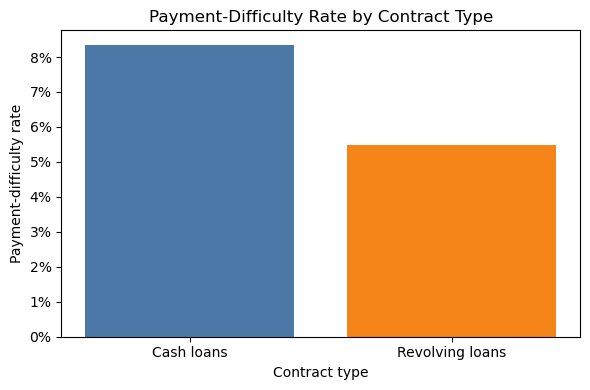

The output shows the dictionary label definition, the overall labeled-event rate, and contract-type labeled-event rates.


In [5]:
# Document the supplied label, then summarize its prevalence overall and by contract type.
target_definition = pd.DataFrame([('dictionary definition', '1 = payment difficulties: late payment more than unspecified X days on at least one of first unspecified Y installments; 0 = all others'), ('business-statement wording', 'default risk'), ('labeling status', 'payment-difficulty label; X/Y and conventional default definition are not supplied')], columns=['item', 'value'])
display(target_definition)
display(pd.DataFrame({'rows': [len(train)], 'target_count': [int(train['TARGET'].sum())], 'target_rate': [train['TARGET'].mean()]}))
contract_rates = rate_by_group(train, 'NAME_CONTRACT_TYPE')
display(contract_rates)
# Visualize the contract-type comparison with a rate axis expressed as a percentage.
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(contract_rates['NAME_CONTRACT_TYPE'], contract_rates['target_rate'], color=['#4C78A8', '#F58518'])
ax.set(title='Payment-Difficulty Rate by Contract Type', xlabel='Contract type', ylabel='Payment-difficulty rate')
ax.yaxis.set_major_formatter(lambda value, _: f'{value:.0%}')
plt.tight_layout()
plt.show()
print('The output shows the dictionary label definition, the overall labeled-event rate, and contract-type labeled-event rates.')

#### Interpretation
The labeled payment-difficulty rate is 8.07% in train and differs between cash loans (8.35%) and revolving loans (5.48%). These are supplied-label outcome rates, not validated default rates, because the dictionary does not define the delinquency threshold or conventional default horizon.

### Q5. Are train and test comparable in feature availability, missingness, categories, and sentinel values?

In [6]:
# Compare schemas, missingness, category support, sentinels, and numeric distributions across train and test.
train_only = sorted(set(train.columns) - set(test.columns))
test_only = sorted(set(test.columns) - set(train.columns))
common = sorted(set(train.columns).intersection(test.columns))
missing_compare = pd.DataFrame({'column': common, 'train_missing_rate': [train[column].isna().mean() for column in common], 'test_missing_rate': [test[column].isna().mean() for column in common]})
missing_compare['absolute_difference'] = (missing_compare['train_missing_rate'] - missing_compare['test_missing_rate']).abs()
category_rows = []
for column in [column for column in common if train[column].dtype == 'object']:
    train_levels, test_levels = set(train[column].dropna().astype(str)), set(test[column].dropna().astype(str))
    category_rows.append({'column': column, 'train_only_levels': sorted(train_levels - test_levels), 'test_only_levels': sorted(test_levels - train_levels), 'train_levels': len(train_levels), 'test_levels': len(test_levels)})
category_compare = pd.DataFrame(category_rows)
sentinel_compare = pd.DataFrame({'table': ['train', 'test'], 'DAYS_EMPLOYED_365243_rate': [(train['DAYS_EMPLOYED'] == 365243).mean(), (test['DAYS_EMPLOYED'] == 365243).mean()]})
numeric_rows = []
for column in [column for column in common if pd.api.types.is_numeric_dtype(train[column]) and column != 'SK_ID_CURR']:
    train_q = train[column].quantile([0.01, 0.25, 0.50, 0.75, 0.99])
    test_q = test[column].quantile([0.01, 0.25, 0.50, 0.75, 0.99])
    train_iqr = train_q.loc[0.75] - train_q.loc[0.25]
    numeric_rows.append({'column': column, 'train_median': train_q.loc[0.50], 'test_median': test_q.loc[0.50], 'median_difference': test_q.loc[0.50] - train_q.loc[0.50], 'median_difference_over_train_iqr': (test_q.loc[0.50] - train_q.loc[0.50]) / train_iqr if train_iqr else np.nan, 'train_p01': train_q.loc[0.01], 'test_p01': test_q.loc[0.01], 'train_p99': train_q.loc[0.99], 'test_p99': test_q.loc[0.99]})
numeric_compare = pd.DataFrame(numeric_rows).sort_values('median_difference_over_train_iqr', key=lambda values: values.abs(), ascending=False)
display(pd.DataFrame({'train_only_columns': [train_only], 'test_only_columns': [test_only], 'common_columns': [len(common)]}))
display(missing_compare.sort_values('absolute_difference', ascending=False).head(15))
display(category_compare.loc[category_compare['train_only_levels'].map(len).gt(0) | category_compare['test_only_levels'].map(len).gt(0)])
display(sentinel_compare)
display(numeric_compare.head(20))
print('The output shows schema differences, missingness and category-level differences, sentinel prevalence, and the largest numeric median/quantile shifts.')

,train_only_columns,test_only_columns,common_columns
0,[TARGET],[],121


,column,train_missing_rate,test_missing_rate,absolute_difference
36,EXT_SOURCE_1,0.5638,0.4212,0.1426
38,EXT_SOURCE_3,0.1983,0.1778,0.0204
35,ENTRANCES_MODE,0.5035,0.4837,0.0198
34,ENTRANCES_MEDI,0.5035,0.4837,0.0198
33,ENTRANCES_AVG,0.5035,0.4837,0.0198
68,FLOORSMAX_MEDI,0.4976,0.4784,0.0192
69,FLOORSMAX_MODE,0.4976,0.4784,0.0192
67,FLOORSMAX_AVG,0.4976,0.4784,0.0192
117,YEARS_BEGINEXPLUATATION_MODE,0.4878,0.4689,0.0189
115,YEARS_BEGINEXPLUATATION_AVG,0.4878,0.4689,0.0189


,column,train_only_levels,test_only_levels,train_levels,test_levels
0,CODE_GENDER,[XNA],[],3,2
8,NAME_FAMILY_STATUS,[Unknown],[],6,5
10,NAME_INCOME_TYPE,[Maternity leave],[],8,7


,table,DAYS_EMPLOYED_365243_rate
0,train,0.1801
1,test,0.1903


,column,train_median,test_median,median_difference,median_difference_over_train_iqr,train_p01,test_p01,train_p99,test_p99
9,AMT_REQ_CREDIT_BUREAU_YEAR,1.0000,2.0000,1.0000,0.3333,0.0000,0.0000,8.0000,8.0000
2,AMT_GOODS_PRICE,"450,000.0000","396,000.0000","-54,000.0000",-0.1224,"67,500.0000","54,000.0000","1,800,000.0000","1,800,000.0000"
1,AMT_CREDIT,"513,531.0000","450,000.0000","-63,531.0000",-0.1179,"76,410.0000","62,554.5000","1,854,000.0000","1,864,152.0000"
3,AMT_INCOME_TOTAL,"147,150.0000","157,500.0000","10,350.0000",0.1150,"45,000.0000","54,000.0000","472,500.0000","517,500.0000"
24,DAYS_LAST_PHONE_CHANGE,-757.0000,-863.0000,-106.0000,-0.0818,"-3,149.0000","-3,360.0000",0.0000,0.0000
0,AMT_ANNUITY,"24,903.0000","26,199.0000","1,296.0000",0.0717,"6,182.9100","5,762.3400","70,006.5000","78,862.5000"
11,APARTMENTS_MEDI,0.0864,0.0926,0.0062,0.0684,0.0021,0.0021,0.5501,0.5756
77,LIVINGAPARTMENTS_MODE,0.0771,0.0817,0.0046,0.0597,0.0028,0.0037,0.4885,0.5234
10,APARTMENTS_AVG,0.0876,0.0928,0.0052,0.0573,0.0021,0.0021,0.5449,0.5670
36,EXT_SOURCE_3,0.5353,0.5191,-0.0162,-0.0542,0.0647,0.0801,0.8328,0.8246


The output shows schema differences, missingness and category-level differences, sentinel prevalence, and the largest numeric median/quantile shifts.


#### Interpretation
Train and test have the expected one-column schema difference (`TARGET`), but they are not identical feature populations: external-score missingness, inquiry-year median, loan/goods-price medians, sentinel prevalence, and category levels differ. Fit preprocessing on train and apply it unchanged to test, with explicit handling for unseen or absent categories.

### Q6. Which features have substantial missingness, and is missingness itself associated with repayment difficulty?

,column,missing_count,missing_rate,target_rate_when_missing,target_rate_when_observed,rate_difference
60,COMMONAREA_MODE,214865,0.6987,0.0857,0.0691,0.0166
74,COMMONAREA_MEDI,214865,0.6987,0.0857,0.0691,0.0166
46,COMMONAREA_AVG,214865,0.6987,0.0857,0.0691,0.0166
82,NONLIVINGAPARTMENTS_MEDI,213514,0.6943,0.0858,0.0691,0.0167
54,NONLIVINGAPARTMENTS_AVG,213514,0.6943,0.0858,0.0691,0.0167
68,NONLIVINGAPARTMENTS_MODE,213514,0.6943,0.0858,0.0691,0.0167
84,FONDKAPREMONT_MODE,210295,0.6839,0.0862,0.0689,0.0173
52,LIVINGAPARTMENTS_AVG,210199,0.6835,0.0862,0.0689,0.0173
66,LIVINGAPARTMENTS_MODE,210199,0.6835,0.0862,0.0689,0.0173
80,LIVINGAPARTMENTS_MEDI,210199,0.6835,0.0862,0.0689,0.0173


,external_score_missing_count,rows,target_rate
0,0,109589,0.0730
1,1,161013,0.0818
2,2,36737,0.0992
3,3,172,0.0814


,bureau_enquiry_missing_count,rows,target_rate
0,0,265992,0.0772
1,6,41519,0.1034


,condition,field,rows,missing_rate
0,FLAG_OWN_CAR = Y,OWN_CAR_AGE missing,104587,0.0000
1,FLAG_OWN_CAR = N,OWN_CAR_AGE missing,202924,1.0000
2,DAYS_EMPLOYED = 365243,OCCUPATION_TYPE missing,55374,1.0000
3,DAYS_EMPLOYED != 365243,OCCUPATION_TYPE missing,252137,0.1627


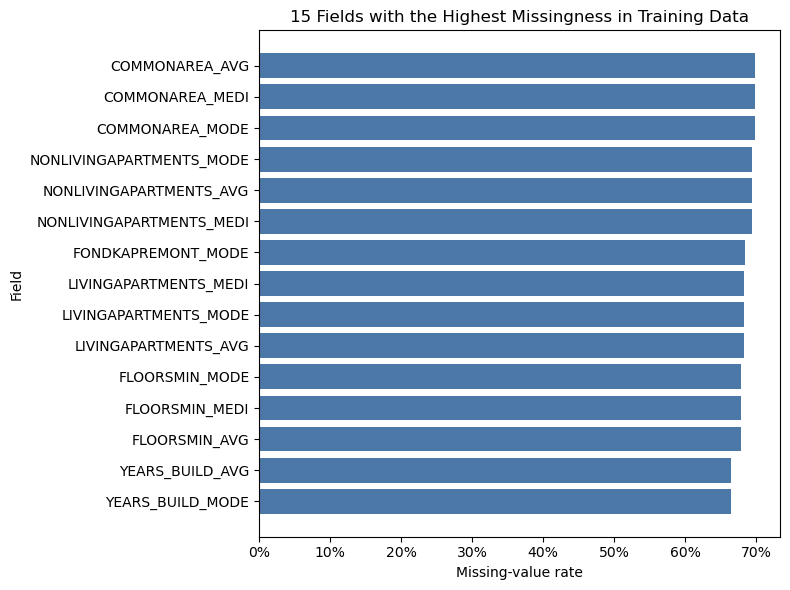

The output shows per-field missingness, joint external/bureau missingness groups, and selected conditional-missingness rates.


In [7]:
# Measure feature-level missingness and compare TARGET rates for missing versus observed records.
missing_rows = []
for column in train.columns.drop(['SK_ID_CURR', 'TARGET']):
    missing = train[column].isna()
    missing_rows.append({'column': column, 'missing_count': int(missing.sum()), 'missing_rate': missing.mean(), 'target_rate_when_missing': train.loc[missing, 'TARGET'].mean() if missing.any() else np.nan, 'target_rate_when_observed': train.loc[~missing, 'TARGET'].mean(), 'rate_difference': (train.loc[missing, 'TARGET'].mean() - train.loc[~missing, 'TARGET'].mean()) if missing.any() else np.nan})
missing_report = pd.DataFrame(missing_rows).sort_values('missing_rate', ascending=False)
display(missing_report.head(30))
missing_features = train.columns.drop(['SK_ID_CURR', 'TARGET'])
joint_missing = train.assign(total_missing_feature_count=train[missing_features].isna().sum(axis=1), external_score_missing_count=train[['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']].isna().sum(axis=1), bureau_enquiry_missing_count=train[inquiry_columns].isna().sum(axis=1))
display(joint_missing.groupby('external_score_missing_count').agg(rows=('TARGET', 'size'), target_rate=('TARGET', 'mean')).reset_index())
display(joint_missing.groupby('bureau_enquiry_missing_count').agg(rows=('TARGET', 'size'), target_rate=('TARGET', 'mean')).reset_index())
conditional_missing = pd.DataFrame([{'condition': 'FLAG_OWN_CAR = Y', 'field': 'OWN_CAR_AGE missing', 'rows': int((train['FLAG_OWN_CAR'] == 'Y').sum()), 'missing_rate': train.loc[train['FLAG_OWN_CAR'] == 'Y', 'OWN_CAR_AGE'].isna().mean()}, {'condition': 'FLAG_OWN_CAR = N', 'field': 'OWN_CAR_AGE missing', 'rows': int((train['FLAG_OWN_CAR'] == 'N').sum()), 'missing_rate': train.loc[train['FLAG_OWN_CAR'] == 'N', 'OWN_CAR_AGE'].isna().mean()}, {'condition': 'DAYS_EMPLOYED = 365243', 'field': 'OCCUPATION_TYPE missing', 'rows': int(train['DAYS_EMPLOYED'].eq(365243).sum()), 'missing_rate': train.loc[train['DAYS_EMPLOYED'].eq(365243), 'OCCUPATION_TYPE'].isna().mean()}, {'condition': 'DAYS_EMPLOYED != 365243', 'field': 'OCCUPATION_TYPE missing', 'rows': int((~train['DAYS_EMPLOYED'].eq(365243)).sum()), 'missing_rate': train.loc[~train['DAYS_EMPLOYED'].eq(365243), 'OCCUPATION_TYPE'].isna().mean()}])
display(conditional_missing)
# Plot the most-missing fields to make the magnitude of missingness easier to compare.
plot_missing = missing_report.head(15).sort_values('missing_rate')
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(plot_missing['column'], plot_missing['missing_rate'], color='#4C78A8')
ax.set(title='15 Fields with the Highest Missingness in Training Data', xlabel='Missing-value rate', ylabel='Field')
ax.xaxis.set_major_formatter(lambda value, _: f'{value:.0%}')
plt.tight_layout()
plt.show()
print('The output shows per-field missingness, joint external/bureau missingness groups, and selected conditional-missingness rates.')

#### Interpretation
Missingness is structured: building fields are frequently missing, car age is missing exactly when car ownership is `N`, and occupation is missing for every employment-sentinel record. Missing external scores and bureau-enquiry fields also have different labeled-event rates, so treatment should be feature-family aware; the associations are not causal evidence.

### Q7. Does the `DAYS_EMPLOYED = 365243` sentinel define a distinct risk segment?

In [8]:
# Treat the documented employment sentinel as its own group and describe its composition and outcome rate.
sentinel_frame = train.assign(employment_group=np.where(train['DAYS_EMPLOYED'].eq(365243), '365243 sentinel', 'non-sentinel'), age_years=-train['DAYS_BIRTH'] / 365.25, occupation_missing=train['OCCUPATION_TYPE'].isna())
sentinel_summary = sentinel_frame.groupby('employment_group').agg(rows=('TARGET', 'size'), target_rate=('TARGET', 'mean'), mean_age_years=('age_years', 'mean'), occupation_missing_rate=('occupation_missing', 'mean'), work_phone_rate=('FLAG_EMP_PHONE', 'mean')).reset_index()
display(sentinel_summary)
display(rate_by_group(sentinel_frame, 'employment_group'))
display(sentinel_frame.groupby(['employment_group', 'NAME_INCOME_TYPE']).agg(rows=('TARGET', 'size'), target_rate=('TARGET', 'mean')).reset_index().sort_values(['employment_group', 'rows'], ascending=[True, False]).head(20))
print('The output shows sentinel and non-sentinel group sizes, labeled-event rates, and selected descriptive context fields.')

,employment_group,rows,target_rate,mean_age_years,occupation_missing_rate,work_phone_rate
0,365243 sentinel,55374,0.0540,59.7126,1.0000,0.0000
1,non-sentinel,252137,0.0866,40.4357,0.1627,1.0000


,employment_group,rows,target_count,target_rate
1,non-sentinel,252137,21835,0.0866
0,365243 sentinel,55374,2990,0.0540


,employment_group,NAME_INCOME_TYPE,rows,target_rate
0,365243 sentinel,Pensioner,55352,0.0539
1,365243 sentinel,Unemployed,22,0.3636
8,non-sentinel,Working,158774,0.0959
3,non-sentinel,Commercial associate,71617,0.0748
6,non-sentinel,State servant,21703,0.0575
7,non-sentinel,Student,18,0.0000
2,non-sentinel,Businessman,10,0.0000
5,non-sentinel,Pensioner,10,0.0000
4,non-sentinel,Maternity leave,5,0.4000


The output shows sentinel and non-sentinel group sizes, labeled-event rates, and selected descriptive context fields.


#### Interpretation
The employment sentinel identifies a materially different group: it is predominantly pensioners, older on average, always missing occupation, and has a lower labeled-event rate than non-sentinel records. Preserve a separate sentinel indicator rather than converting it to employment duration.

### Q8. How do income, credit amount, annuity, and a requested-payment-to-income proxy relate to repayment difficulty?

,feature,bin,rows,target_count,target_rate
0,AMT_INCOME_TOTAL,"(25649.999, 99000.0]",63671,5225,0.0821
1,AMT_INCOME_TOTAL,"(99000.0, 135000.0]",85756,7365,0.0859
2,AMT_INCOME_TOTAL,"(135000.0, 162000.0]",35453,3079,0.0868
3,AMT_INCOME_TOTAL,"(162000.0, 225000.0]",75513,6084,0.0806
4,AMT_INCOME_TOTAL,"(225000.0, 117000000.0]",47118,3072,0.0652
5,AMT_CREDIT,"(44999.999, 254700.0]",64925,4699,0.0724
6,AMT_CREDIT,"(254700.0, 432000.0]",58098,5329,0.0917
7,AMT_CREDIT,"(432000.0, 604152.0]",61552,6189,0.1005
8,AMT_CREDIT,"(604152.0, 900000.0]",64024,5029,0.0785
9,AMT_CREDIT,"(900000.0, 4050000.0]",58912,3579,0.0608


,count,mean,std,min,25%,50%,75%,max
AMT_INCOME_TOTAL,"307,511.0000","168,797.9193","237,123.1463","25,650.0000","112,500.0000","147,150.0000","202,500.0000","117,000,000.0000"
AMT_CREDIT,"307,511.0000","599,025.9997","402,490.7770","45,000.0000","270,000.0000","513,531.0000","808,650.0000","4,050,000.0000"
AMT_ANNUITY,"307,499.0000","27,108.5739","14,493.7373","1,615.5000","16,524.0000","24,903.0000","34,596.0000","258,025.5000"
AMT_GOODS_PRICE,"307,233.0000","538,396.2074","369,446.4605","40,500.0000","238,500.0000","450,000.0000","679,500.0000","4,050,000.0000"
requested_payment_to_income,"307,499.0000",0.1809,0.0946,0.0002,0.1148,0.1628,0.2291,1.8760


,measure,value,note
0,requested_payment_to_income > 1,33.0000,requires unit and income-verification check be...
1,requested_payment_to_income maximum,1.8760,requires unit and income-verification check be...
2,AMT_INCOME_TOTAL maximum,"117,000,000.0000",requires income-verification check before lite...


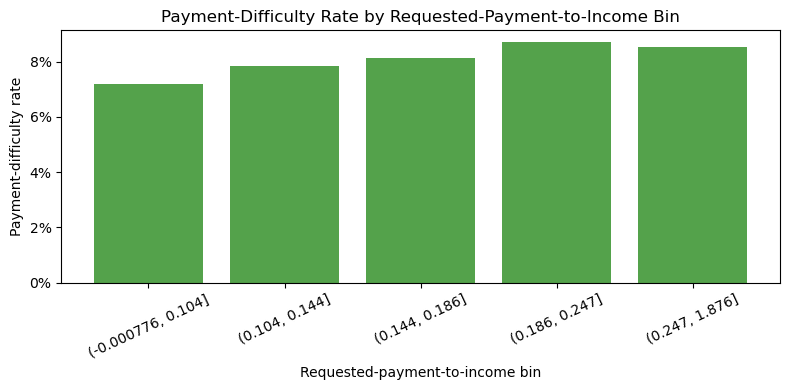

The output shows training-data bins, numeric summaries, and selected values requiring unit or verification checks before literal underwriting use.


In [9]:
# Create a descriptive annuity-to-income proxy and compare outcome rates across equal-frequency value bins.
financial = train.assign(requested_payment_to_income=train['AMT_ANNUITY'] / train['AMT_INCOME_TOTAL'])
financial_report = pd.concat([binned_target_rate(financial, column) for column in ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'requested_payment_to_income']], ignore_index=True)
display(financial_report)
display(financial[['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'requested_payment_to_income']].describe().T)
ratio_check = pd.DataFrame({'measure': ['requested_payment_to_income > 1', 'requested_payment_to_income maximum', 'AMT_INCOME_TOTAL maximum'], 'value': [int(financial['requested_payment_to_income'].gt(1).sum()), financial['requested_payment_to_income'].max(), financial['AMT_INCOME_TOTAL'].max()], 'note': ['requires unit and income-verification check before literal use', 'requires unit and income-verification check before literal use', 'requires income-verification check before literal use']})
display(ratio_check)
# Plot the requested-payment-to-income bins; bins contain roughly equal counts after missing values are excluded.
ratio_bins = financial_report.loc[financial_report['feature'].eq('requested_payment_to_income')].copy()
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(ratio_bins['bin'].astype(str), ratio_bins['target_rate'], color='#54A24B')
ax.set(title='Payment-Difficulty Rate by Requested-Payment-to-Income Bin', xlabel='Requested-payment-to-income bin', ylabel='Payment-difficulty rate')
ax.tick_params(axis='x', rotation=25)
ax.yaxis.set_major_formatter(lambda value, _: f'{value:.0%}')
plt.tight_layout()
plt.show()
print('The output shows training-data bins, numeric summaries, and selected values requiring unit or verification checks before literal underwriting use.')

#### Interpretation
Income, requested credit, annuity, goods price, and the payment-to-income proxy show non-flat binned outcome patterns, but the extremes are not monotonic and should not be used as simple policy cutoffs. The 33 ratios above one and the maximum income of 117,000,000 require unit and income-verification checks before literal underwriting use.

### Q9. Which employment and stability features—employment duration, income type, occupation, registration age, and contact changes—show the clearest relationship with risk?

In [10]:
# Exclude the sentinel from duration bins while retaining categorical employment and stability comparisons.
stability = train.assign(employment_days_clean=train['DAYS_EMPLOYED'].mask(train['DAYS_EMPLOYED'].eq(365243)))
categorical_stability = []
for column in ['NAME_INCOME_TYPE', 'OCCUPATION_TYPE', 'ORGANIZATION_TYPE']:
    categorical_stability.append(named_rate_by_group(stability, column).head(20))
display(pd.concat(categorical_stability, ignore_index=True))
numeric_stability = pd.concat([binned_target_rate(stability, column) for column in ['employment_days_clean', 'DAYS_REGISTRATION', 'DAYS_LAST_PHONE_CHANGE']], ignore_index=True)
display(numeric_stability)
print('The output shows category and numeric-bin group sizes and labeled-event rates for the specified employment and stability fields.')

,feature,value,rows,target_count,target_rate
0,NAME_INCOME_TYPE,Maternity leave,5,2,0.4000
1,NAME_INCOME_TYPE,Unemployed,22,8,0.3636
2,NAME_INCOME_TYPE,Working,158774,15224,0.0959
3,NAME_INCOME_TYPE,Commercial associate,71617,5360,0.0748
4,NAME_INCOME_TYPE,State servant,21703,1249,0.0575
5,NAME_INCOME_TYPE,Pensioner,55362,2982,0.0539
6,NAME_INCOME_TYPE,Student,18,0,0.0000
7,NAME_INCOME_TYPE,Businessman,10,0,0.0000
8,OCCUPATION_TYPE,Low-skill Laborers,2093,359,0.1715
9,OCCUPATION_TYPE,Drivers,18603,2107,0.1133


,feature,bin,rows,target_count,target_rate
0,employment_days_clean,"(-17912.001, -3675.8]",50428,2616,0.0519
1,employment_days_clean,"(-3675.8, -2160.0]",50446,3583,0.0710
2,employment_days_clean,"(-2160.0, -1250.0]",50411,4585,0.0910
3,employment_days_clean,"(-1250.0, -617.0]",50427,5380,0.1067
4,employment_days_clean,"(-617.0, 0.0]",50425,5671,0.1125
5,DAYS_REGISTRATION,"(-24672.001, -8230.0]",61507,3762,0.0612
6,DAYS_REGISTRATION,"(-8230.0, -5459.0]",61514,4666,0.0759
7,DAYS_REGISTRATION,"(-5459.0, -3537.0]",61491,5343,0.0869
8,DAYS_REGISTRATION,"(-3537.0, -1491.0]",61536,5292,0.0860
9,DAYS_REGISTRATION,"(-1491.0, 0.0]",61463,5762,0.0937


The output shows category and numeric-bin group sizes and labeled-event rates for the specified employment and stability fields.


#### Interpretation
Employment duration, registration recency, and phone-change recency show differing binned outcome rates, while several income and occupation categories are sparse. These patterns are descriptive and likely entangled with age, pensioner status, missing occupation, and application composition; sparse categories should not support standalone conclusions.

### Q10. How informative are external scores and credit-bureau enquiry counts, including their missingness?

,feature,missing_count,missing_rate,target_rate_when_missing,target_rate_when_observed
0,EXT_SOURCE_1,173378,0.5638,0.0852,0.0750
1,EXT_SOURCE_2,660,0.0021,0.0788,0.0807
2,EXT_SOURCE_3,60965,0.1983,0.0931,0.0777


,feature,bin,rows,target_count,target_rate
0,EXT_SOURCE_1,"(0.013600000000000001, 0.296]",26827,3911,0.1458
1,EXT_SOURCE_1,"(0.296, 0.438]",26826,2344,0.0874
2,EXT_SOURCE_1,"(0.438, 0.573]",26827,1706,0.0636
3,EXT_SOURCE_1,"(0.573, 0.71]",26826,1277,0.0476
4,EXT_SOURCE_1,"(0.71, 0.963]",26827,816,0.0304
5,EXT_SOURCE_2,"(-0.0009999183, 0.34]",61371,9337,0.1521
6,EXT_SOURCE_2,"(0.34, 0.512]",61371,5622,0.0916
7,EXT_SOURCE_2,"(0.512, 0.608]",61371,4320,0.0704
8,EXT_SOURCE_2,"(0.608, 0.682]",61377,3293,0.0537
9,EXT_SOURCE_2,"(0.682, 0.855]",61361,2201,0.0359


,feature,group,rows,target_rate
0,AMT_REQ_CREDIT_BUREAU_HOUR,missing,41519,0.1034
1,AMT_REQ_CREDIT_BUREAU_HOUR,positive,1626,0.0806
2,AMT_REQ_CREDIT_BUREAU_HOUR,zero,264366,0.0772
3,AMT_REQ_CREDIT_BUREAU_DAY,missing,41519,0.1034
4,AMT_REQ_CREDIT_BUREAU_DAY,positive,1489,0.0947
5,AMT_REQ_CREDIT_BUREAU_DAY,zero,264503,0.0771
6,AMT_REQ_CREDIT_BUREAU_WEEK,missing,41519,0.1034
7,AMT_REQ_CREDIT_BUREAU_WEEK,positive,8536,0.0783
8,AMT_REQ_CREDIT_BUREAU_WEEK,zero,257456,0.0772
9,AMT_REQ_CREDIT_BUREAU_MON,missing,41519,0.1034


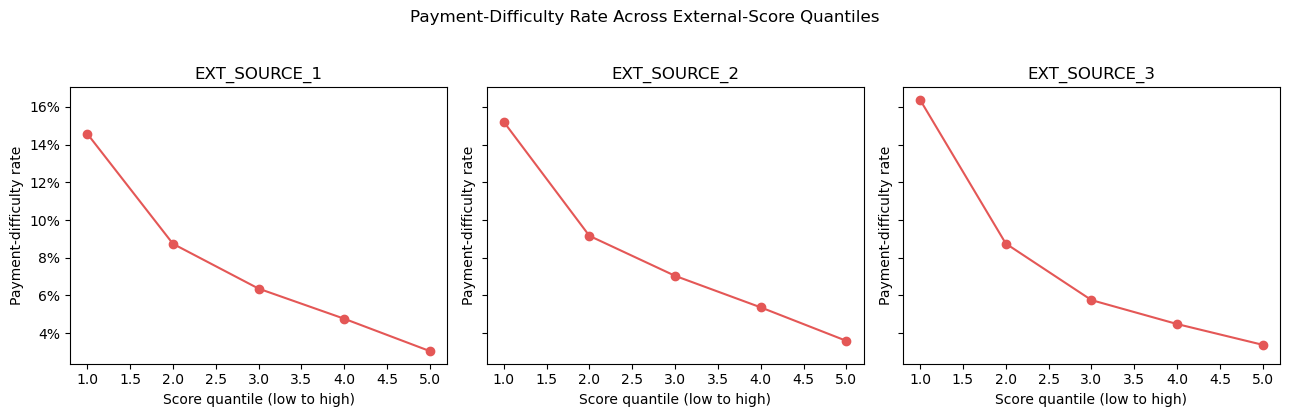

The output shows external-score availability and binned labeled-event rates, plus zero/missing/positive enquiry-count groups by lookback window.


In [11]:
# Summarize external-score bins and bureau-enquiry states, including missingness as a separate state.
external_columns = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']
external_bins = pd.concat([binned_target_rate(train, column) for column in external_columns], ignore_index=True)
external_missing = pd.DataFrame([{'feature': column, 'missing_count': int(train[column].isna().sum()), 'missing_rate': train[column].isna().mean(), 'target_rate_when_missing': train.loc[train[column].isna(), 'TARGET'].mean(), 'target_rate_when_observed': train.loc[train[column].notna(), 'TARGET'].mean()} for column in external_columns])
inquiry_columns = ['AMT_REQ_CREDIT_BUREAU_HOUR', 'AMT_REQ_CREDIT_BUREAU_DAY', 'AMT_REQ_CREDIT_BUREAU_WEEK', 'AMT_REQ_CREDIT_BUREAU_MON', 'AMT_REQ_CREDIT_BUREAU_QRT', 'AMT_REQ_CREDIT_BUREAU_YEAR']
inquiry_rows = []
for column in inquiry_columns:
    group = np.select([train[column].isna(), train[column].eq(0)], ['missing', 'zero'], default='positive')
    table = pd.DataFrame({'group': group, 'TARGET': train['TARGET']}).groupby('group').agg(rows=('TARGET', 'size'), target_rate=('TARGET', 'mean')).reset_index()
    table.insert(0, 'feature', column)
    inquiry_rows.append(table)
display(external_missing)
display(external_bins)
display(pd.concat(inquiry_rows, ignore_index=True))
# Plot each normalized external score separately because their scales and missingness differ.
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, feature in zip(axes, external_columns):
    feature_bins = external_bins.loc[external_bins['feature'].eq(feature)].reset_index(drop=True)
    ax.plot(feature_bins.index + 1, feature_bins['target_rate'], marker='o', color='#E45756')
    ax.set(title=feature, xlabel='Score quantile (low to high)', ylabel='Payment-difficulty rate')
    ax.yaxis.set_major_formatter(lambda value, _: f'{value:.0%}')
fig.suptitle('Payment-Difficulty Rate Across External-Score Quantiles', y=1.03)
plt.tight_layout()
plt.show()
print('The output shows external-score availability and binned labeled-event rates, plus zero/missing/positive enquiry-count groups by lookback window.')

#### Interpretation
All three external scores have strongly ordered binned outcome rates in observed data, and score/bureau-enquiry missingness has a different outcome rate from observed or zero values. Their apparent predictive value does not resolve provenance, timing, consent, explainability, or permitted-use documentation.

### Q11. Do housing, regional, and address-consistency variables add useful information, or mainly act as socioeconomic/geographic proxies?

In [12]:
# Derive an address-mismatch count and describe housing and regional groups without inferring causality.
address_flags = ['REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION', 'REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY']
housing = train.assign(address_mismatch_count=train[address_flags].sum(axis=1))
housing_cats = pd.concat([named_rate_by_group(housing, column) for column in ['NAME_HOUSING_TYPE', 'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY']], ignore_index=True)
housing_numeric = pd.concat([binned_target_rate(housing, column) for column in ['REGION_POPULATION_RELATIVE', 'DAYS_REGISTRATION', 'TOTALAREA_MODE', 'address_mismatch_count']], ignore_index=True)
display(housing_cats)
display(housing_numeric)
print('The output shows category and numeric-bin group sizes and labeled-event rates for the specified housing, regional, and address-consistency fields.')

,feature,value,rows,target_count,target_rate
0,NAME_HOUSING_TYPE,Rented apartment,4881,601,0.1231
1,NAME_HOUSING_TYPE,With parents,14840,1736,0.1170
2,NAME_HOUSING_TYPE,Municipal apartment,11183,955,0.0854
3,NAME_HOUSING_TYPE,Co-op apartment,1122,89,0.0793
4,NAME_HOUSING_TYPE,House / apartment,272868,21272,0.0780
5,NAME_HOUSING_TYPE,Office apartment,2617,172,0.0657
6,REGION_RATING_CLIENT,3,48330,5366,0.1110
7,REGION_RATING_CLIENT,2,226984,17907,0.0789
8,REGION_RATING_CLIENT,1,32197,1552,0.0482
9,REGION_RATING_CLIENT_W_CITY,3,43860,5001,0.1140


,feature,bin,rows,target_count,target_rate
0,REGION_POPULATION_RELATIVE,"(-0.00071, 0.00887]",63155,5649,0.0894
1,REGION_POPULATION_RELATIVE,"(0.00887, 0.0166]",60969,4830,0.0792
2,REGION_POPULATION_RELATIVE,"(0.0166, 0.0207]",63143,6028,0.0955
3,REGION_POPULATION_RELATIVE,"(0.0207, 0.0308]",64025,4947,0.0773
4,REGION_POPULATION_RELATIVE,"(0.0308, 0.0725]",56219,3371,0.0600
5,DAYS_REGISTRATION,"(-24672.001, -8230.0]",61507,3762,0.0612
6,DAYS_REGISTRATION,"(-8230.0, -5459.0]",61514,4666,0.0759
7,DAYS_REGISTRATION,"(-5459.0, -3537.0]",61491,5343,0.0869
8,DAYS_REGISTRATION,"(-3537.0, -1491.0]",61536,5292,0.0860
9,DAYS_REGISTRATION,"(-1491.0, 0.0]",61463,5762,0.0937


The output shows category and numeric-bin group sizes and labeled-event rates for the specified housing, regional, and address-consistency fields.


#### Interpretation
Housing type, regional ratings, population, building area, registration timing, and address-mismatch count have different outcome rates. Because they can encode geography and socioeconomic conditions, association alone is not enough to approve them as model inputs; they need proxy-risk and fair-lending review.

### Q12. Are document/contact flags and application timing associated with risk, or do they reflect operational-process differences?

In [13]:
# Compare document/contact indicators and application timing groups, retaining group sizes for context.
document_contact = indicator_columns
flag_rows = []
for column in document_contact:
    table = train.groupby(column).agg(rows=('TARGET', 'size'), target_rate=('TARGET', 'mean')).reset_index().rename(columns={column: 'value'})
    table.insert(0, 'feature', column)
    flag_rows.append(table[['feature', 'value', 'rows', 'target_rate']])
flag_report = pd.concat(flag_rows, ignore_index=True)
timing_report = pd.concat([named_rate_by_group(train, 'WEEKDAY_APPR_PROCESS_START'), named_rate_by_group(train, 'HOUR_APPR_PROCESS_START')], ignore_index=True)
display(flag_report.sort_values(['feature', 'value']).head(80))
display(timing_report)
print('The output shows document/contact indicator prevalence and labeled-event rates, plus weekday and hour application-time groups.')

,feature,value,rows,target_rate
6,FLAG_CONT_MOBILE,0,574,0.0784
7,FLAG_CONT_MOBILE,1,306937,0.0807
40,FLAG_DOCUMENT_10,0,307504,0.0807
41,FLAG_DOCUMENT_10,1,7,0.0000
42,FLAG_DOCUMENT_11,0,306308,0.0808
43,FLAG_DOCUMENT_11,1,1203,0.0623
44,FLAG_DOCUMENT_12,0,307509,0.0807
45,FLAG_DOCUMENT_12,1,2,0.0000
46,FLAG_DOCUMENT_13,0,306427,0.0809
47,FLAG_DOCUMENT_13,1,1084,0.0277


,feature,value,rows,target_count,target_rate
0,WEEKDAY_APPR_PROCESS_START,TUESDAY,53901,4501,0.0835
1,WEEKDAY_APPR_PROCESS_START,WEDNESDAY,51934,4238,0.0816
2,WEEKDAY_APPR_PROCESS_START,FRIDAY,50338,4101,0.0815
3,WEEKDAY_APPR_PROCESS_START,THURSDAY,50591,4098,0.0810
4,WEEKDAY_APPR_PROCESS_START,SUNDAY,16181,1283,0.0793
5,WEEKDAY_APPR_PROCESS_START,SATURDAY,33852,2670,0.0789
6,WEEKDAY_APPR_PROCESS_START,MONDAY,50714,3934,0.0776
7,HOUR_APPR_PROCESS_START,0,40,6,0.1500
8,HOUR_APPR_PROCESS_START,23,41,5,0.1220
9,HOUR_APPR_PROCESS_START,6,5842,645,0.1104


The output shows document/contact indicator prevalence and labeled-event rates, plus weekday and hour application-time groups.


#### Interpretation
Several document flags have very small positive groups, making their observed rates unstable, while weekday/hour patterns may reflect operations as much as applicant risk. Do not assign document, contact, or timing variables underwriting meaning until process origin, timing, and operational confounding are understood.

### Q13. Which candidate features are appropriate for modeling, which are only suitable for monitoring, and which create fairness, leakage, or explainability concerns?

In [14]:
# Record a provisional modeling, monitoring, or exclusion decision for the major feature families.
feature_register = pd.DataFrame([
    ('SK_ID_CURR', 'exclude', 'identifier'), ('TARGET', 'exclude', 'outcome label'), ('AMT_INCOME_TOTAL / AMT_CREDIT / AMT_ANNUITY', 'candidate', 'application-time capacity fields'), ('DAYS_EMPLOYED plus sentinel flag', 'candidate after treatment', 'documented sentinel'), ('EXT_SOURCE_1/2/3', 'needs approval', 'opaque provenance and missingness'), ('AMT_REQ_CREDIT_BUREAU_*', 'candidate after missingness treatment', 'limited enquiry counts'), ('CODE_GENDER / NAME_FAMILY_STATUS / DAYS_BIRTH', 'monitor or exclude', 'protected/restricted context'), ('regional and address fields', 'needs fair-lending review', 'potential geographic proxies'), ('document/contact flags', 'needs operational review', 'may reflect process rather than applicant risk')
], columns=['feature/group', 'current decision', 'documented basis'])
display(feature_register)
print('The output shows the current feature-decision register with candidate, exclusion, monitoring, and approval statuses.')

,feature/group,current decision,documented basis
0,SK_ID_CURR,exclude,identifier
1,TARGET,exclude,outcome label
2,AMT_INCOME_TOTAL / AMT_CREDIT / AMT_ANNUITY,candidate,application-time capacity fields
3,DAYS_EMPLOYED plus sentinel flag,candidate after treatment,documented sentinel
4,EXT_SOURCE_1/2/3,needs approval,opaque provenance and missingness
5,AMT_REQ_CREDIT_BUREAU_*,candidate after missingness treatment,limited enquiry counts
6,CODE_GENDER / NAME_FAMILY_STATUS / DAYS_BIRTH,monitor or exclude,protected/restricted context
7,regional and address fields,needs fair-lending review,potential geographic proxies
8,document/contact flags,needs operational review,may reflect process rather than applicant risk


The output shows the current feature-decision register with candidate, exclusion, monitoring, and approval statuses.


#### Interpretation
The register provides a provisional separation between candidate application-time variables and fields that are excluded, monitoring-only, or awaiting governance. It is not approval to deploy any candidate feature; timing, fairness, source, and reason-code gaps remain open.

### Q14. Once child tables are added, what share of applicants has historical credit/payment data, and how should those tables be aggregated safely to one row per `SK_ID_CURR`?

In [15]:
# Check whether each dictionary-described child table is available before proposing joins or aggregations.
child_tables = ['bureau.csv', 'bureau_balance.csv', 'previous_application.csv', 'POS_CASH_balance.csv', 'credit_card_balance.csv', 'installments_payments.csv']
child_status = pd.DataFrame({'table': child_tables, 'present_in_workspace': [(data_dir / table).exists() for table in child_tables], 'required_action': ['defer coverage, key, grain, temporal, and aggregation analysis until supplied'] * len(child_tables)})
display(child_status)
print('The output shows whether each dictionary-described child table is available for the planned coverage and aggregation analysis.')

,table,present_in_workspace,required_action
0,bureau.csv,False,"defer coverage, key, grain, temporal, and aggr..."
1,bureau_balance.csv,False,"defer coverage, key, grain, temporal, and aggr..."
2,previous_application.csv,False,"defer coverage, key, grain, temporal, and aggr..."
3,POS_CASH_balance.csv,False,"defer coverage, key, grain, temporal, and aggr..."
4,credit_card_balance.csv,False,"defer coverage, key, grain, temporal, and aggr..."
5,installments_payments.csv,False,"defer coverage, key, grain, temporal, and aggr..."


The output shows whether each dictionary-described child table is available for the planned coverage and aggregation analysis.


#### Interpretation
No dictionary-described historical child table is available, so prior credit, repayment, utilization, and historical-application features cannot yet be measured or joined. Validate their grain, timing, coverage, and aggregation before using them in EDA or modeling.

### Q15. Does the evidence support the claim that the modeled population is thin-file or unbanked?

In [16]:
# Report available credit-information proxies while checking whether banking-status fields actually exist.
thin_file_proxy = pd.DataFrame([{'measure': column, 'observed_rate': train[column].notna().mean(), 'definition': 'non-missing application-level external score'} for column in ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']] + [{'measure': column, 'observed_rate': train[column].notna().mean(), 'definition': 'non-missing application-level enquiry-count field'} for column in inquiry_columns])
banked_columns = [column for column in train.columns if any(token in column.lower() for token in ['bank', 'account', 'deposit', 'checking', 'savings'])]
display(thin_file_proxy)
display(pd.DataFrame({'banked_or_unbanked_indicator_columns': [banked_columns], 'child_tables_available': [int(child_status['present_in_workspace'].sum())]}))
print('The output shows external-score/enquiry-field availability and whether the supplied application schema contains a banked/unbanked indicator.')

,measure,observed_rate,definition
0,EXT_SOURCE_1,0.4362,non-missing application-level external score
1,EXT_SOURCE_2,0.9979,non-missing application-level external score
2,EXT_SOURCE_3,0.8017,non-missing application-level external score
3,AMT_REQ_CREDIT_BUREAU_HOUR,0.8650,non-missing application-level enquiry-count field
4,AMT_REQ_CREDIT_BUREAU_DAY,0.8650,non-missing application-level enquiry-count field
5,AMT_REQ_CREDIT_BUREAU_WEEK,0.8650,non-missing application-level enquiry-count field
6,AMT_REQ_CREDIT_BUREAU_MON,0.8650,non-missing application-level enquiry-count field
7,AMT_REQ_CREDIT_BUREAU_QRT,0.8650,non-missing application-level enquiry-count field
8,AMT_REQ_CREDIT_BUREAU_YEAR,0.8650,non-missing application-level enquiry-count field


,banked_or_unbanked_indicator_columns,child_tables_available
0,[],0


The output shows external-score/enquiry-field availability and whether the supplied application schema contains a banked/unbanked indicator.


#### Interpretation
The supplied application data does not establish that the population is unbanked or thin-file. External-score and enquiry-field availability are not banking-status measures, and absent bureau child tables prevent a defensible credit-history coverage assessment.

### Q16. What baseline data and measurement design are required to assess the stated approval, loss, NIM, processing-time, and rigid-rule-model improvement claims?

In [17]:
# Map each business claim to its minimum data requirements and the evidence currently supplied.
kpi_requirements = pd.DataFrame([
    ('approval-rate change', 'approval/decline decisions, eligibility population, incumbent and proposed policy', 'missing'),
    ('portfolio loss rate', 'funded balances, realized losses, recoveries, cohort window', 'missing'),
    ('net interest margin', 'APR/fees, funding cost, balances, charge-offs, time window', 'missing'),
    ('underwriting processing time', 'application and decision timestamps plus workflow events', 'missing'),
    ('rule-model improvement', 'incumbent score/decision, policy cutoffs, and matched outcomes', 'missing'),
    ('AUC-ROC development metric', 'labeled training applications and a defined validation split', 'partial: TARGET is supplied')
], columns=['claim/KPI', 'minimum required data', 'current availability'])
display(kpi_requirements)
print('The output shows the required sources and current availability for each Business Problem Statement KPI or comparison claim.')

,claim/KPI,minimum required data,current availability
0,approval-rate change,"approval/decline decisions, eligibility popula...",missing
1,portfolio loss rate,"funded balances, realized losses, recoveries, ...",missing
2,net interest margin,"APR/fees, funding cost, balances, charge-offs,...",missing
3,underwriting processing time,application and decision timestamps plus workf...,missing
4,rule-model improvement,"incumbent score/decision, policy cutoffs, and ...",missing
5,AUC-ROC development metric,labeled training applications and a defined va...,partial: TARGET is supplied


The output shows the required sources and current availability for each Business Problem Statement KPI or comparison claim.


#### Interpretation
The current files cannot quantify the Business Problem Statement's approval, loss, NIM, processing-time, or incumbent-rule improvement claims. Those claims require production decision, financial, workflow, and comparison-baseline data rather than further analysis of the application files.

### Q17. Is the current dataset and proposed modeling setup ready to substantiate AUC-ROC ≥ 0.78 and map probabilities to approved risk tiers?

In [18]:
# Assess whether the supplied files support development, validation, and operational risk-tier claims.
readiness = pd.DataFrame([
    ('labeled development data', 'yes', 'application_train.csv has TARGET'),
    ('target horizon/threshold', 'partial', 'dictionary leaves X and Y unspecified'),
    ('application/cohort timestamp for temporal validation', 'no', 'no current-application date field documented'),
    ('labeled external test/holdout', 'no', 'application_test.csv has no TARGET'),
    ('feature timing register', 'yes', 'Q3 register created'),
    ('incumbent baseline', 'no', 'no current rule/model score or decision supplied'),
    ('risk-tier cutoffs and economics', 'no', 'no risk appetite, pricing, capacity, or loss policy supplied'),
    ('adverse-action reason design', 'no', 'no approved reason-code policy supplied')
], columns=['readiness item', 'status', 'evidence'])
display(readiness)
print('The output shows which development, validation, and risk-tier prerequisites are present, partial, or absent in the supplied materials.')

,readiness item,status,evidence
0,labeled development data,yes,application_train.csv has TARGET
1,target horizon/threshold,partial,dictionary leaves X and Y unspecified
2,application/cohort timestamp for temporal vali...,no,no current-application date field documented
3,labeled external test/holdout,no,application_test.csv has no TARGET
4,feature timing register,yes,Q3 register created
5,incumbent baseline,no,no current rule/model score or decision supplied
6,risk-tier cutoffs and economics,no,"no risk appetite, pricing, capacity, or loss p..."
7,adverse-action reason design,no,no approved reason-code policy supplied


The output shows which development, validation, and risk-tier prerequisites are present, partial, or absent in the supplied materials.


#### Interpretation
The labeled train file can support internal development and validation after a split is defined, but cannot establish temporal generalization, the AUC target, or production risk tiers. Label-horizon details, application dates, a labeled external holdout, incumbent baseline, tier policy, pricing/loss economics, and adverse-action design remain unavailable.

## Final completeness check

### What has been missed against the Business Problem Statement, the dictionary, the six standing checks, and what an underwriter would refuse to believe?

In [19]:
# Consolidate unresolved data, governance, and credibility gaps identified across the EDA.
completeness = pd.DataFrame([
    ('Business Problem Statement', 'unbanked population claim', 'no banked/unbanked indicator or deposit-account source', 'obtain verified banking-status definition and source or remove/qualify claim'),
    ('Business Problem Statement', 'default-risk wording', 'TARGET is payment difficulty with unspecified X/Y', 'use dictionary label wording or obtain formal default definition'),
    ('Business Problem Statement', 'approval/loss/NIM/processing-time promises', 'no decisions, economics, workflow timestamps, or incumbent baseline', 'obtain KPI sources and comparison design'),
    ('Dictionary', 'child-table feature families', 'six described child files are absent', 'run Q1–Q3 and Q14 when supplied'),
    ('Standing checks', 'application-time availability', 'external-score provenance and timing are undocumented', 'obtain source, consent, refresh, and availability documentation'),
    ('Underwriter credibility', 'stated income and employment', 'no verification source', 'separate stated from verified capacity'),
    ('Underwriter credibility', 'selection bias', 'no declined applications or approval-policy records', 'obtain application-decision population and policy history'),
    ('Underwriter credibility', 'outcome maturity and vintage', 'no application date or outcome window thresholds', 'obtain cohorts, observation window, and X/Y label definition'),
    ('Underwriter credibility', 'risk tiers and economics', 'no pricing, expected loss, capacity, or cut-off policy', 'obtain approved tier and decision policy'),
    ('Underwriter credibility', 'fair lending and reason codes', 'no approved governance, monitoring, or adverse-action mapping', 'obtain compliance-approved feature and reason-code policy')
], columns=['review lens', 'item', 'current gap', 'needed next step'])
display(completeness)
print('The output shows the remaining claim-validation, data, timing, economics, and governance gaps not resolved by the supplied application files.')

,review lens,item,current gap,needed next step
0,Business Problem Statement,unbanked population claim,no banked/unbanked indicator or deposit-accoun...,obtain verified banking-status definition and ...
1,Business Problem Statement,default-risk wording,TARGET is payment difficulty with unspecified X/Y,use dictionary label wording or obtain formal ...
2,Business Problem Statement,approval/loss/NIM/processing-time promises,"no decisions, economics, workflow timestamps, ...",obtain KPI sources and comparison design
3,Dictionary,child-table feature families,six described child files are absent,run Q1–Q3 and Q14 when supplied
4,Standing checks,application-time availability,external-score provenance and timing are undoc...,"obtain source, consent, refresh, and availabil..."
5,Underwriter credibility,stated income and employment,no verification source,separate stated from verified capacity
6,Underwriter credibility,selection bias,no declined applications or approval-policy re...,obtain application-decision population and pol...
7,Underwriter credibility,outcome maturity and vintage,no application date or outcome window thresholds,"obtain cohorts, observation window, and X/Y la..."
8,Underwriter credibility,risk tiers and economics,"no pricing, expected loss, capacity, or cut-of...",obtain approved tier and decision policy
9,Underwriter credibility,fair lending and reason codes,"no approved governance, monitoring, or adverse...",obtain compliance-approved feature and reason-...


The output shows the remaining claim-validation, data, timing, economics, and governance gaps not resolved by the supplied application files.


#### Interpretation
The remaining gaps are missing-data and governance gaps, not issues resolvable by additional transformation of the two application files. Resolve or qualify them before presenting the work as customer-level, default-risk, unbanked-lending, financial-impact, or production-underwriting analysis.

## Results and implications

This EDA establishes that the two supplied tables are application-level partitions with complete, unique `SK_ID_CURR` values and no overlap. The train label has an 8.07% payment-difficulty rate, with a lower rate for revolving than cash loans. It should not be described as a fully defined default-rate outcome because the delinquency threshold and performance horizon are unspecified.

Several data issues require explicit preparation rules: `DAYS_EMPLOYED = 365243` is a meaningful sentinel rather than a duration; the test file contains one `REGION_RATING_CLIENT_W_CITY = -1`; `XNA` is an unknown-category value; some requested-payment-to-income and income values need verification; and missingness is often structural. In particular, car age is absent when car ownership is `N`, occupation is absent for employment-sentinel records, and building-related variables have substantial missingness. These are not candidates for a single generic imputation rule.

The strongest descriptive relationships appear in the observed external-score quantiles, where payment-difficulty rates are strongly ordered, and in selected missingness states. These relationships are promising for exploratory model development but remain conditional on documentation of timing, provenance, consent, explainability, and permitted use. Housing, regional, address, document, contact, and timing variables may be predictive, but they are also potential socioeconomic, geographic, or operational proxies and need fairness and process review before any model use.

Accordingly, the next analytics step should be a carefully governed development exercise: fit all preprocessing on training data only; encode sentinel and missingness states deliberately; retain group-size checks for sparse categories; use an internal validation split while labeling it non-temporal; and exclude identifiers and the outcome from predictors. The work cannot yet substantiate claims about unbanked or thin-file borrowers, approval lift, loss reduction, NIM, turnaround time, a comparison with incumbent rules, production risk tiers, or temporal generalization. Those claims require the missing historical, operational, financial, baseline, and governance data identified above.

## AI Disclosure

I used AI as described in class for this assignment. AI was used to research, synthesize all the data in the csv files, data dictionary, and business problem statement, and create a plan and all the code for the eda file. I wrote interpretations following each question I wanted answered in the EDA, and then had AI validate and re-word my interpretations. Everything went well--but using AI for this did require more iteration to get what I desired than I had originally anticipated. 